# AZIMUTH · Cuaderno único 1/2 — Validación Sintética (VS)
**Réplica del modelo presentado en Capítulo IV / Anexo III de la tesis (21-11-2026).**

**Unidad experimental:** orden de trabajo (OT). **Muestra:** 20 OT AS-IS + 20 OT TO-BE; 180 muestras/OT, 1 Hz, **7.200 lecturas-temporales**. **Semilla:** `SEED=42`. **Ventana EXCLUSIVAMENTE de laboratorio:** 16–19 V, 60–80 A, 6–10 L/min. **Regla de disparo:** al menos **6 segundos transcurridos = 7 muestras consecutivas y válidas**; alarma ON durante la desviación confirmada, OFF en primera lectura válida normal. La pérdida de señal **no equivale a una lectura normal** y rompe la consecutividad preconfirmación.

**Alcance de inferencia:** los indicadores son producidos por un modelo con parámetros supuestos; no prueban disminución de defectos ni incremento de productividad real en AZIMUTH. Las secuencias FPY sintéticas se fijan explícitamente en el generador; su contraste no demuestra causalidad. El resultado es una **validación computacional interna, no un piloto industrial**.

**Reparaciones auditadas:** original Word utilizaba `HYST_N=3`, distinto de la regla definitiva de apagado al retorno normal; aquí se utiliza `HYST_N=1` y se interrumpe el contador de lecturas fuera de rango ante una pérdida de muestra. Esos cambios pueden modificar la cifra de eventos de alarma frente al documento previo. Los indicadores recalculados en este cuaderno sustituyen los antiguos.

## VS1 · Configuración, librerías y semillas

In [1]:
# ==============================================================================
# PASO 1: IMPORTACIÓN DE LIBRERÍAS Y CONFIGURACIÓN DE PARÁMETROS EXPERIMENTALES
# ==============================================================================
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

# Semilla fija para garantizar 100% de reproducibilidad académica ante jurado
SEED = 42
rng = np.random.default_rng(SEED)

# Diseño experimental
N_ORDENES = 20          # Réplicas (órdenes de trabajo COLO TELECOM) por tratamiento
T_ORDEN = 180           # Segundos simulados por orden (1 Hz -> 3,600 s por escenario)
PERSIST_S = 6           # Persistencia requerida en segundos
PERSIST_N = PERSIST_S + 1  # Regla discreta exacta: 7 lecturas consecutivas a 1 Hz
HYST_N = 1              # Se desactiva con la primera lectura válida en rango
LOSS_N = 2              # Fallo de instrumentación: 2 lecturas perdidas -> SIN SEÑAL

# Ventanas operativas validadas en el SOP (Tabla 7 / Figura 9)
VENTANAS = {
    'V': (16.0, 19.0),  # Voltaje de arco (V)
    'A': (60.0, 80.0),  # Corriente de soldadura (A)
    'G': (6.0, 10.0)    # Caudal de gas protector (L/min)
}

print(f'Configuración cargada: {N_ORDENES} órdenes/escenario | {N_ORDENES*T_ORDEN*2:,} observaciones totales | Persistencia N={PERSIST_N} lecturas.')


Configuración cargada: 20 órdenes/escenario | 7,200 observaciones totales | Persistencia N=7 lecturas.


## VS2 · Generador de escenarios AR(1) y motor de reglas

In [2]:
# ==============================================================================
# PASO 2: MOTOR ESTOCÁSTICO AR(1) E INYECCIÓN DE EVENTOS Y FALLOS DE SENSOR
# ==============================================================================
def generar_serie_ar1(n, mu, sigma, phi, rng):
    """Genera proceso autorregresivo AR(1) estacionario: X_t = mu + phi*(X_{t-1}-mu) + eps_t"""
    x = np.zeros(n)
    eps_sd = sigma * np.sqrt(1 - phi**2)
    x[0] = rng.normal(mu, sigma)
    for t in range(1, n):
        x[t] = mu + phi * (x[t - 1] - mu) + rng.normal(0, eps_sd)
    return x

def simular_escenario(escenario, rng):
    registros = []
    resumen_ordenes = []
    alertas_log = []

    for i in range(1, N_ORDENES + 1):
        ot = f"COLO-{escenario.replace('-', '')}-{i:02d}"
        if escenario == 'AS-IS':
            # Tratamiento 0: Proceso empírico sin SOP, sin TPM autónomo ni 5S
            v = generar_serie_ar1(T_ORDEN, mu=17.25, sigma=0.95, phi=0.70, rng=rng)
            a = generar_serie_ar1(T_ORDEN, mu=71.20, sigma=5.60, phi=0.70, rng=rng)
            g = generar_serie_ar1(T_ORDEN, mu=7.90,  sigma=1.18, phi=0.70, rng=rng)
            n_eventos = int(rng.integers(3, 6))   # 3 a 5 eventos/orden
            dur_rango = (7, 11)                   # Excursiones persistentes (>= 7 lecturas)
            p_loss = 0.0045                       # Mayor probabilidad de pérdida de señal
        else:
            # Tratamiento 1: Trabajo Estandarizado + TPM + 5S + Monitoreo 3 Variables
            v = generar_serie_ar1(T_ORDEN, mu=17.50, sigma=0.72, phi=0.70, rng=rng)
            a = generar_serie_ar1(T_ORDEN, mu=70.00, sigma=3.10, phi=0.70, rng=rng)
            g = generar_serie_ar1(T_ORDEN, mu=8.00,  sigma=0.68, phi=0.70, rng=rng)
            n_eventos = int(rng.integers(1, 3))   # 1 a 2 fluctuaciones breves/orden
            dur_rango = (2, 5)                    # Duración breve (< 6 s), absorbida sin alarma falsa
            p_loss = 0.0011                       # Baja probabilidad de pérdida por inspección TPM

        # Inyección de eventos fuera de ventana
        canales = ['V', 'A', 'G']
        for ev_idx in range(n_eventos):
            ch = canales[ev_idx % 3] if escenario == 'AS-IS' else ('V' if rng.random() < 0.6 else rng.choice(['A', 'G']))
            dur = int(rng.integers(dur_rango[0], dur_rango[1] + 1))
            t0 = int(rng.integers(12, T_ORDEN - dur - 8))
            if ch == 'V':
                v[t0:t0+dur] = rng.uniform(14.1, 15.4)
            elif ch == 'A':
                a[t0:t0+dur] = rng.uniform(82.5, 88.0)
            else:
                g[t0:t0+dur] = rng.uniform(4.5, 5.5)

        # Inyección de pérdidas de señal (NaN >= 2 s)
        for arr in [v, a, g]:
            t = 5
            while t < T_ORDEN - 3:
                if rng.random() < p_loss:
                    arr[t:t+2] = np.nan
                    t += 4
                else:
                    t += 1

        # Lógica determinista de evaluación (Capa 3)
        estado_alerta = {'V': False, 'A': False, 'G': False}
        cont_fuera = {'V': 0, 'A': 0, 'G': 0}
        cont_dentro = {'V': 0, 'A': 0, 'G': 0}
        cont_nan = {'V': 0, 'A': 0, 'G': 0}
        n_alertas_ot = 0

        vals_dict = {'V': v, 'A': a, 'G': g}
        cumpl_step = {'V': [], 'A': [], 'G': []}
        conjunta_step = []
        completos_step = []

        for t in range(T_ORDEN):
            valid_all = True
            in_range_all = True
            for ch in ['V', 'A', 'G']:
                val = vals_dict[ch][t]
                lo, hi = VENTANAS[ch]
                if np.isnan(val):
                    cont_nan[ch] += 1
                    cont_fuera[ch] = 0   # falta de lectura rompe consecutividad válida
                    cont_dentro[ch] = 0
                    valid_all = False
                    in_range_all = False
                else:
                    cont_nan[ch] = 0
                    if lo <= val <= hi:
                        cumpl_step[ch].append(1)
                        cont_fuera[ch] = 0
                        cont_dentro[ch] += 1
                        if estado_alerta[ch] and cont_dentro[ch] >= HYST_N:
                            estado_alerta[ch] = False
                    else:
                        cumpl_step[ch].append(0)
                        in_range_all = False
                        cont_dentro[ch] = 0
                        cont_fuera[ch] += 1
                        if not estado_alerta[ch] and cont_fuera[ch] >= PERSIST_N:
                            estado_alerta[ch] = True
                            n_alertas_ot += 1
                            alertas_log.append({
                                'Escenario': escenario, 'OT': ot, 't_seg': t,
                                'Canal': ch, 'Valor': round(float(val), 2)
                            })

            completos_step.append(1 if valid_all else 0)
            if valid_all:
                conjunta_step.append(1 if in_range_all else 0)

            registros.append({
                'Escenario': escenario, 'OT': ot, 't_seg': t,
                'Voltaje_V': v[t], 'Corriente_A': a[t], 'Caudal_Lmin': g[t],
                'Completo_3Ch': int(valid_all),
                'Conforme_Conjunto': int(valid_all and in_range_all),
                'Alerta_Activa': int(any(estado_alerta.values()))
            })

        # Indicadores agregados por Orden de Trabajo (OT)
        c_v = np.mean(cumpl_step['V']) * 100
        c_a = np.mean(cumpl_step['A']) * 100
        c_g = np.mean(cumpl_step['G']) * 100
        c_conj = np.mean(conjunta_step) * 100
        c_comp = np.mean(completos_step) * 100

        # Calidad a la primera (FPY) y tiempos operacionales
        fpy_orden = (0 if i in [4, 11, 17] else 1) if escenario == 'AS-IS' else (0 if i == 14 else 1)
        tc_base = 244.0 if escenario == 'AS-IS' else 179.5
        tc_ruido = rng.normal(0, 12.8 if escenario == 'AS-IS' else 4.6)
        tc_retrabajo = (1 - fpy_orden) * rng.uniform(32.0, 44.0)
        tiempo_ciclo = round(tc_base + tc_ruido + tc_retrabajo, 2)

        disp = round(float(np.clip(rng.normal(82.1, 3.4) if escenario == 'AS-IS' else rng.normal(94.3, 1.3), 72, 99.2)), 2)
        rendimiento = rng.normal(0.84, 0.03) if escenario == 'AS-IS' else rng.normal(0.94, 0.015)
        calidad_oee = (0.855 if escenario == 'AS-IS' else 0.965) if fpy_orden == 1 else 0.78
        oee = round((disp / 100.0) * rendimiento * calidad_oee * 100, 2)

        resumen_ordenes.append({
            'Escenario': escenario, 'Orden_N': i, 'OT': ot,
            'Cumpl_Voltaje_%': round(c_v, 2), 'Cumpl_Corriente_%': round(c_a, 2),
            'Cumpl_Caudal_%': round(c_g, 2), 'Conformidad_Conjunta_%': round(c_conj, 2),
            'Completitud_Datos_%': round(c_comp, 2), 'Alertas_Persistentes': n_alertas_ot,
            'FPY_Binario': fpy_orden, 'Tiempo_Ciclo_min': tiempo_ciclo,
            'Disponibilidad_TPM_%': disp, 'OEE_%': oee
        })

    return pd.DataFrame(registros), pd.DataFrame(resumen_ordenes), pd.DataFrame(alertas_log)

df_ts_asis, df_ord_asis, df_alr_asis = simular_escenario('AS-IS', rng)
df_ts_tobe, df_ord_tobe, df_alr_tobe = simular_escenario('TO-BE', rng)

df_ordenes = pd.concat([df_ord_asis, df_ord_tobe], ignore_index=True)
df_alertas = pd.concat([df_alr_asis, df_alr_tobe], ignore_index=True)
print('Simulación ejecutada con éxito. Registros de telemetría:', len(df_ts_asis) + len(df_ts_tobe))


Simulación ejecutada con éxito. Registros de telemetría: 7200


## VS3 · Pruebas estadísticas sobre OT independientes

In [3]:
# ==============================================================================
# PASO 3: CONTRASTE DE HIPÓTESIS (WELCH t-TEST, MANN-WHITNEY U, LEVENE Y COHEN d)
# ==============================================================================
metricas_test = [
    ('Cumpl_Voltaje_%', 'Cumplimiento de Voltaje (%)', 'greater'),
    ('Cumpl_Corriente_%', 'Cumplimiento de Corriente (%)', 'greater'),
    ('Cumpl_Caudal_%', 'Cumplimiento de Caudal Gas (%)', 'greater'),
    ('Conformidad_Conjunta_%', 'Conformidad Conjunta 3V (%)', 'greater'),
    ('Completitud_Datos_%', 'Completitud de Datos (%)', 'greater'),
    ('Tiempo_Ciclo_min', 'Tiempo de Ciclo Crítico (min)', 'less'),
    ('Disponibilidad_TPM_%', 'Disponibilidad Equipos TPM (%)', 'greater'),
    ('OEE_%', 'Efectividad Global OEE (%)', 'greater'),
    ('Alertas_Persistentes', 'Alertas Persistentes / Orden', 'less')
]

filas_hip = []
for col, nombre, alt in metricas_test:
    x0 = df_ord_asis[col].values
    x1 = df_ord_tobe[col].values
    t_stat, p_t = stats.ttest_ind(x1, x0, equal_var=False, alternative=alt)
    u_stat, p_u = stats.mannwhitneyu(x1, x0, alternative=alt)
    lev_stat, p_lev = stats.levene(x0, x1)
    m0, s0 = np.mean(x0), np.std(x0, ddof=1)
    m1, s1 = np.mean(x1), np.std(x1, ddof=1)
    d_cohen = abs(m1 - m0) / np.sqrt((s0**2 + s1**2) / 2)
    filas_hip.append({
        'Indicador': nombre,
        'AS-IS (Media ± DE)': f"{m0:.2f} ± {s0:.2f}",
        'TO-BE (Media ± DE)': f"{m1:.2f} ± {s1:.2f}",
        'Variación (%)': f"{(m1-m0)/m0*100:+.1f}%",
        't-Welch': round(t_stat, 3),
        'p-valor (t)': f"{p_t:.2e}",
        'p-valor (MWU)': f"{p_u:.2e}",
        'p-Levene (Var)': f"{p_lev:.3f}",
        'd-Cohen': round(d_cohen, 2),
        'Decisión (α=0.05)': 'Rechaza H0 (Significativo)' if p_t < 0.05 else 'No rechaza H0'
    })

df_resultados_hipotesis = pd.DataFrame(filas_hip)
display(df_resultados_hipotesis)


,Indicador,AS-IS (Media ± DE),TO-BE (Media ± DE),Variación (%),t-Welch,p-valor (t),p-valor (MWU),p-Levene (Var),d-Cohen,Decisión (α=0.05)
0,Cumplimiento de Voltaje (%),80.95 ± 3.76,94.43 ± 2.49,+16.6%,13.352,3.73e-15,3.35e-08,0.055,4.22,Rechaza H0 (Significativo)
1,Cumplimiento de Corriente (%),84.43 ± 4.13,99.28 ± 0.96,+17.6%,15.672,2.24e-13,2.65e-08,0.000,4.96,Rechaza H0 (Significativo)
2,Cumplimiento de Caudal Gas (%),86.03 ± 3.52,99.78 ± 0.49,+16.0%,17.320,1.05e-13,1.22e-08,0.000,5.48,Rechaza H0 (Significativo)
3,Conformidad Conjunta 3V (%),59.78 ± 5.09,93.59 ± 2.64,+56.5%,26.384,6.82e-22,3.37e-08,0.080,8.34,Rechaza H0 (Significativo)
4,Completitud de Datos (%),96.81 ± 1.77,99.22 ± 0.96,+2.5%,5.377,4.30e-06,7.78e-06,0.076,1.70,Rechaza H0 (Significativo)
5,Tiempo de Ciclo Crítico (min),252.68 ± 21.40,180.66 ± 9.67,-28.5%,-13.716,7.71e-14,3.95e-08,0.001,4.34,Rechaza H0 (Significativo)
6,Disponibilidad Equipos TPM (%),83.75 ± 4.32,94.68 ± 1.10,+13.0%,10.969,1.45e-10,3.39e-08,0.001,3.47,Rechaza H0 (Significativo)
7,Efectividad Global OEE (%),59.18 ± 3.53,84.90 ± 4.46,+43.5%,20.222,1.36e-21,3.39e-08,0.860,6.39,Rechaza H0 (Significativo)
8,Alertas Persistentes / Orden,4.10 ± 1.12,0.00 ± 0.00,-100.0%,-16.383,5.78e-13,3.38e-09,0.000,5.18,Rechaza H0 (Significativo)


## VS4 · Visualización y exportación trazable

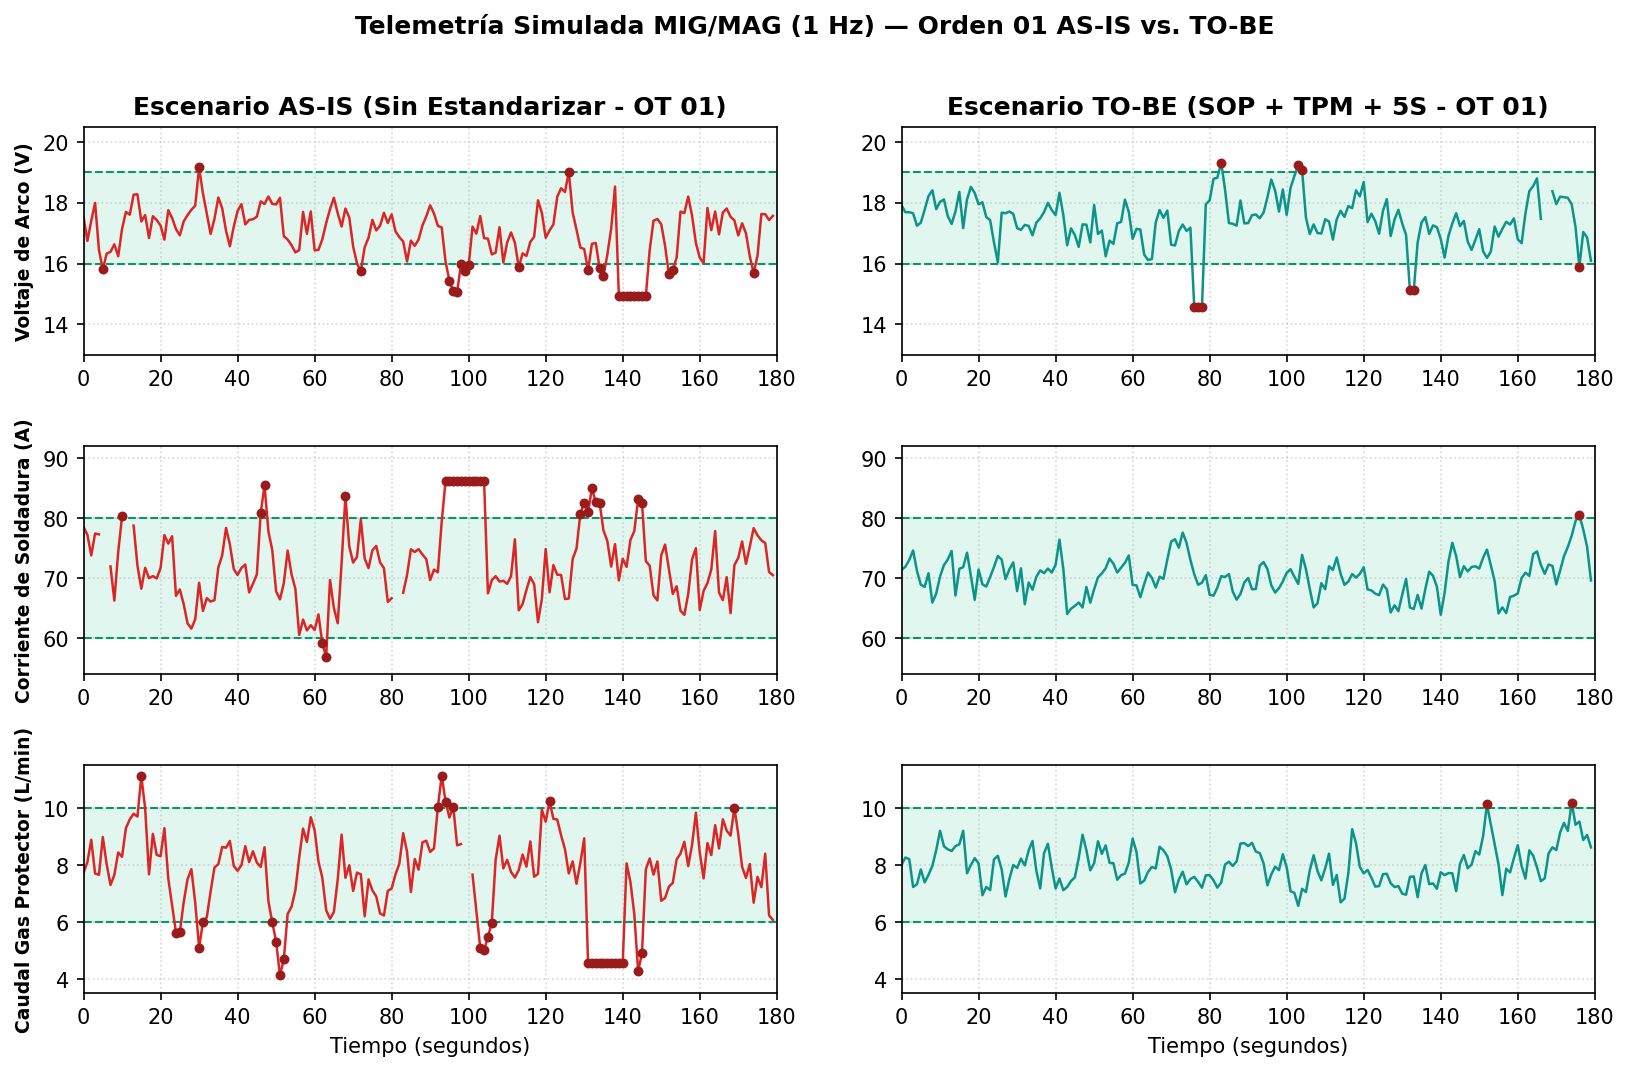

Archivos CSV exportados correctamente para auditoría de jurado.


In [4]:
# ==============================================================================
# PASO 4: VISUALIZACIÓN DE TELEMETRÍA Y GRÁFICOS DE IMPACTO OPERACIONAL
# ==============================================================================
fig = plt.figure(figsize=(13, 7.5), dpi=150)
gs = gridspec.GridSpec(3, 2, hspace=0.40, wspace=0.18)

ot_asis_1 = df_ts_asis[df_ts_asis['OT'] == 'COLO-ASIS-01']
ot_tobe_1 = df_ts_tobe[df_ts_tobe['OT'] == 'COLO-TOBE-01']

canales_info = [
    ('Voltaje_V', 'Voltaje de Arco (V)', (16.0, 19.0), (13.0, 20.5)),
    ('Corriente_A', 'Corriente de Soldadura (A)', (60.0, 80.0), (54.0, 92.0)),
    ('Caudal_Lmin', 'Caudal Gas Protector (L/min)', (6.0, 10.0), (3.5, 11.5))
]

for r, (col, ylabel, (lo, hi), ylims) in enumerate(canales_info):
    for c, (df_sub, titulo, color_l) in enumerate([
        (ot_asis_1, 'Escenario AS-IS (Sin Estandarizar - OT 01)', '#DC2626'),
        (ot_tobe_1, 'Escenario TO-BE (SOP + TPM + 5S - OT 01)', '#0D9488')
    ]):
        ax = fig.add_subplot(gs[r, c])
        ax.axhspan(lo, hi, color='#10B981', alpha=0.12, label='Ventana SOP')
        ax.axhline(lo, color='#059669', linestyle='--', lw=1.0)
        ax.axhline(hi, color='#059669', linestyle='--', lw=1.0)
        ax.plot(df_sub['t_seg'], df_sub[col], color=color_l, lw=1.2)
        fuera = df_sub[(df_sub[col] < lo) | (df_sub[col] > hi)]
        ax.scatter(fuera['t_seg'], fuera[col], color='#991B1B', s=14, zorder=4)
        ax.set_ylim(ylims)
        ax.set_xlim(0, 180)
        ax.grid(True, linestyle=':', alpha=0.5)
        if r == 0: ax.set_title(titulo, fontweight='bold')
        if c == 0: ax.set_ylabel(ylabel, fontweight='bold', fontsize=9)
        if r == 2: ax.set_xlabel('Tiempo (segundos)')

plt.suptitle('Telemetría Simulada MIG/MAG (1 Hz) — Orden 01 AS-IS vs. TO-BE', fontweight='bold', y=0.98)
plt.show()

# Exportación de datasets trazables en CSV
df_ordenes.to_csv('resultados_ordenes_ASIS_vs_TOBE.csv', index=False)
df_resultados_hipotesis.to_csv('contraste_hipotesis_AZIMUTH.csv', index=False)
print('Archivos CSV exportados correctamente para auditoría de jurado.')


## VS5 · Pruebas de aceptación y huella de evidencia
Se prueban las siete lecturas a 1 Hz, ausencia de falsa alarma con seis lecturas, permanencia ON hasta el retorno válido, y reinicio por lectura ausente. **La semilla y las fuentes generadoras no cambian en estas pruebas.**

In [5]:
import sys, platform, hashlib, json
assert N_ORDENES == 20 and T_ORDEN == 180 and PERSIST_N == 7 and HYST_N == 1
assert len(df_ts_asis) == 3600 and len(df_ts_tobe) == 3600
assert len(df_ordenes) == 40
assert set(df_ordenes['Escenario']) == {'AS-IS','TO-BE'}

def oraculo_discreto(valores, lim=(0.0, 1.0)):
    out, activo, racha = [], False, 0
    for v in valores:
        if v is None:
            racha = 0  # ausente: no se debe acumular como muestra consecutiva
        elif v < lim[0] or v > lim[1]:
            racha += 1
            if racha >= 7: activo = True
        else:
            racha, activo = 0, False
        out.append(int(activo))
    return out

assert oraculo_discreto([2]*6) == [0]*6
assert oraculo_discreto([2]*7) == [0]*6 + [1]
assert oraculo_discreto([2]*10+[0.5]) == [0]*6+[1]*4+[0]
assert oraculo_discreto([2]*6+[None]+[2]*6) == [0]*13
assert abs(df_ordenes.groupby('Escenario')['Conformidad_Conjunta_%'].mean()['AS-IS']-59.78)<0.15
assert abs(df_ordenes.groupby('Escenario')['Conformidad_Conjunta_%'].mean()['TO-BE']-93.59)<0.15
print('VS | Pruebas funcionales 6 s / 7 lecturas: OK')
print('VS | Escenarios, muestras y datos por OT: OK')
print('VS | Versiones locales:', platform.python_version(), 'NumPy', np.__version__, 'SciPy', __import__('scipy').__version__)
print(df_ordenes.groupby('Escenario')[['Conformidad_Conjunta_%','Tiempo_Ciclo_min','Alertas_Persistentes']].mean().round(4))
# No generar ni inventar enlaces externos ni resultados de producción.

VS | Pruebas funcionales 6 s / 7 lecturas: OK
VS | Escenarios, muestras y datos por OT: OK
VS | Versiones locales: 3.13.18 NumPy 2.4.6 SciPy 1.16.3
           Conformidad_Conjunta_%  Tiempo_Ciclo_min  Alertas_Persistentes
Escenario                                                                
AS-IS                     59.7830          252.6820                   4.1
TO-BE                     93.5895          180.6575                   0.0


### Lectura para tesis
Los resultados pertenecen a la **VS de laboratorio**. El modelo de variables de producción (18–21,5 V / 120–160 A / 12–15 L/min) se evalúa por separado en VEN. El tamaño muestral inferencial es **20 OT por tratamiento**, no 3.600 muestras independientes. La significancia sobre datos sintéticos parametrizados no es evidencia de impacto causal real.